# 05 · Compounding error: why small per-step mistakes become big failures

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from vlacourse import TableTop, ScriptedExpert

def lane_rollout(policy, T, rng, x0=0.0):
    x, xs = x0, []
    for _ in range(T):
        x = x + policy(x, rng)
        xs.append(x)
    return np.array(xs)

def expert(x, rng):
    return -0.5 * x

def make_learner(eps, support=0.05):
    def learner(x, rng):
        if abs(x) <= support:
            return -0.5 * x + (0.06 if rng.random() < eps else 0.0)
        return rng.normal(0, 0.03)
    return learner

def run_tabletop(env, n_episodes, action_noise=0.0, replay=None, shift=0.0, seed=0):
    rng, wins, recorded = np.random.default_rng(seed), [], []
    for ep in range(n_episodes):
        env.reset(seed=1000 + ep)
        if shift > 0:
            adr = env.model.jnt_qposadr[env.model.joint(f"cube_{env.task['obj']}").id]
            env.data.qpos[adr:adr + 2] += rng.normal(0, shift, 2)
            mujoco.mj_forward(env.model, env.data)
        ex = ScriptedExpert(env)
        acts, done, k = [], False, 0
        while not done:
            if replay is None:
                a = ex.act() + np.r_[rng.normal(0, action_noise, 3), 0, 0, 0, 0]
            else:
                a = replay[ep][min(k, len(replay[ep]) - 1)]
            acts.append(a)
            k += 1
            _, _, done, info = env.step(a)
        wins.append(info["success"])
        recorded.append(acts)
    return float(np.mean(wins)), recorded

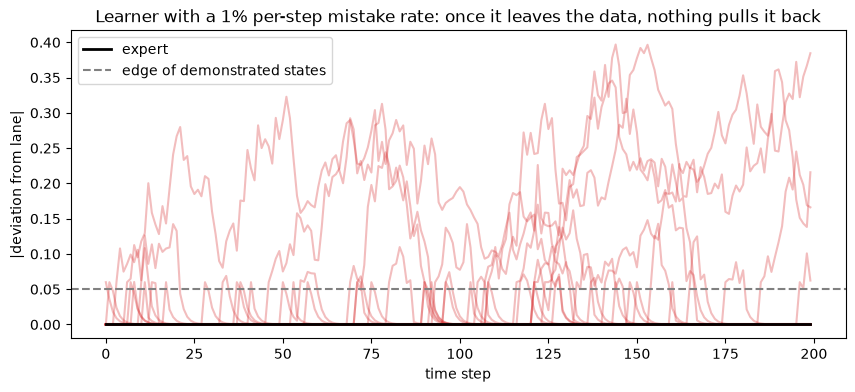

In [2]:
rng = np.random.default_rng(0)
T = 200
plt.figure(figsize=(10, 4))
for _ in range(30):
    plt.plot(np.abs(lane_rollout(make_learner(0.01), T, rng)), color="tab:red", alpha=0.3)
plt.plot(np.abs(lane_rollout(expert, T, rng)), "k", lw=2, label="expert")
plt.axhline(0.05, ls="--", c="gray", label="edge of demonstrated states")
plt.xlabel("time step"); plt.ylabel("|deviation from lane|"); plt.legend()
plt.title("Learner with a 1% per-step mistake rate: once it leaves the data, nothing pulls it back"); plt.show()

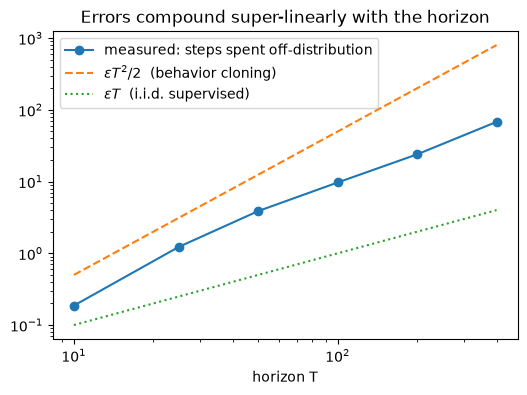

In [3]:
Ts = np.array([10, 25, 50, 100, 200, 400])
eps = 0.01
cost = [np.mean([np.sum(np.abs(lane_rollout(make_learner(eps), T, rng)) > 0.05) for _ in range(300)]) for T in Ts]
plt.figure(figsize=(6, 4))
plt.loglog(Ts, cost, "o-", label="measured: steps spent off-distribution")
plt.loglog(Ts, eps * Ts ** 2 / 2, "--", label=r"$\epsilon T^2/2$  (behavior cloning)")
plt.loglog(Ts, eps * Ts, ":", label=r"$\epsilon T$  (i.i.d. supervised)")
plt.xlabel("horizon T"); plt.legend(); plt.title("Errors compound super-linearly with the horizon"); plt.show()

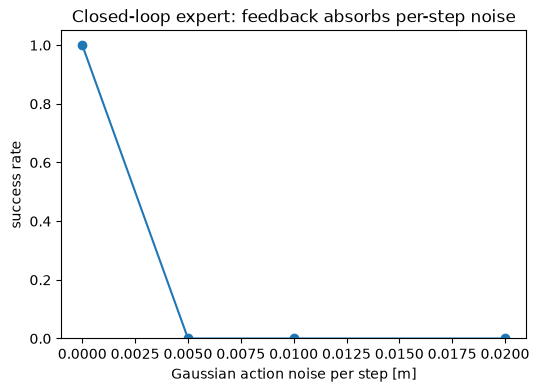

In [4]:
env = TableTop(n_cubes=3, n_trays=1, cameras=(), task_types=("place",))
noise = [0.0, 0.005, 0.01, 0.02]
closed = [run_tabletop(env, 20, action_noise=s)[0] for s in noise]
plt.figure(figsize=(6, 4))
plt.plot(noise, closed, "o-")
plt.xlabel("Gaussian action noise per step [m]"); plt.ylabel("success rate"); plt.ylim(0, 1.05)
plt.title("Closed-loop expert: feedback absorbs per-step noise"); plt.show()

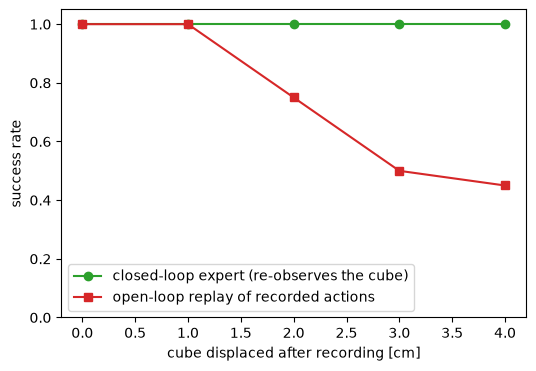

In [5]:
_, demos = run_tabletop(env, 20)
shifts = [0.0, 0.01, 0.02, 0.03, 0.04]
replay = [run_tabletop(env, 20, replay=demos, shift=s)[0] for s in shifts]
closed = [run_tabletop(env, 20, shift=s)[0] for s in shifts]
plt.figure(figsize=(6, 4))
plt.plot(np.array(shifts) * 100, closed, "o-", c="tab:green", label="closed-loop expert (re-observes the cube)")
plt.plot(np.array(shifts) * 100, replay, "s-", c="tab:red", label="open-loop replay of recorded actions")
plt.xlabel("cube displaced after recording [cm]"); plt.ylabel("success rate"); plt.ylim(0, 1.05); plt.legend()
plt.show()